# Data Preparation
## Step 00: Setup & Load

In this step we load all modules and the raw DataFrame.

In [133]:
import numpy as np
import pandas as pd
from pandas.api.types import is_numeric_dtype
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer

from datetime import datetime

pd.set_option("display.max_columns",100)

# loading data
df_raw = pd.read_csv("board_games.csv")

df_raw

,BGGId,Name,Description,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,GoodPlayers,NumOwned,NumWant,NumWish,NumWeightVotes,MfgPlaytime,ComMinPlaytime,ComMaxPlaytime,MfgAgeRec,NumUserRatings,NumComments,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,Family,Kickstarted,ImagePath,Rank:strategygames,Rank:abstracts,Rank:familygames,Rank:thematic,Rank:cgs,Rank:wargames,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
0,2399,Senet,senet ancient egyptian board game similar back...,-3500,1.4769,1.6256,2,2,6.833333,131.142857,0,[],1411,19,133,65,30,30,30,6,713,0,14,1,0,0,NaN,0,https://cf.geekdo-images.com/2gkFXJFYi6RAqkSSm...,21926,731,21926,21926,21926,21926,21926,21926,0,0,0,0,0,1,0,0,Low
1,5546,Marbles,marble play ancient egyptian small ball clay r...,-3000,1.1020,1.2219,1,0,4.500000,1.000000,0,[],417,1,4,49,10,10,10,4,490,0,16,0,0,0,NaN,0,https://cf.geekdo-images.com/6VcU1PvBIO_tel2zV...,21926,21926,21926,21926,21926,21926,21926,821,0,0,0,0,0,0,0,1,Low
2,11726,Knucklebones,backgroundthis game forerunner quotdicequot ga...,-3000,0.0000,0.0000,2,2,NaN,NaN,0,[],93,1,9,0,0,0,0,6,30,0,12,0,0,0,NaN,0,https://cf.geekdo-images.com/GndZmE6t4SRW0erTI...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Low
3,2397,Backgammon,backgammon classic abstract strategy game date...,-3000,2.0182,2.1523,2,2,7.956522,16.000000,2,['2'],18722,23,254,932,30,30,30,8,12238,0,73,2,1,0,3M Bookshelf,0,https://cf.geekdo-images.com/_6HVCuGni6NunlrSj...,21926,132,21926,21926,21926,21926,21926,21926,0,0,0,0,0,1,0,0,Medium
4,1602,The Royal Game of Ur,game publish different name simple race game l...,-2600,1.3000,1.5190,2,2,7.750000,141.000000,0,[],1279,17,192,40,30,30,30,10,605,0,18,0,0,0,The Reliquary Collection (Bibelot Games),0,https://cf.geekdo-images.com/DkRLcDIjKsUIh3Dim...,21926,749,21926,21926,21926,21926,21926,21926,0,0,0,0,0,1,0,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21920,310192,Overboss: A Boss Monster Adventure,overboss rival boss monster emerge dungeon con...,2021,2.0455,2.3383,1,5,6.833333,62.000000,0,[],2386,74,481,22,30,20,30,8,794,0,0,1,0,0,Boss Monster,1,https://cf.geekdo-images.com/t8tLdsAhe5e9tmel4...,21926,21926,517,21926,21926,21926,21926,21926,0,0,0,1,0,0,0,0,High
21921,319579,Crash Octopus,quotwe lose way sail nightmare cargo throw ove...,2021,1.1111,1.2284,1,5,NaN,186.000000,0,[],761,131,441,9,30,20,30,7,270,0,0,0,0,0,NaN,0,https://cf.geekdo-images.com/2nix8SKlJngZREZvW...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,High
21922,307386,Set a Watch: Swords of the Coin,kingdom grave danger mighty adventurer find ki...,2021,2.5000,2.7606,1,4,NaN,NaN,0,[],849,18,129,2,75,60,75,10,111,0,3,1,0,0,NaN,1,https://cf.geekdo-images.com/pMpADO0OpHoxGuwgm...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,High
21923,322560,Maeshowe: an Orkney Saga,accord orkneyinga saga earl rognvald kali kols...,2021,2.0000,2.2672,1,2,12.000000,181.000000,0,[],204,20,90,5,30,15,30,12,67,0,0,0,1,1,NaN,1,https://cf.geekdo-images.com/Ly-3SywXNxrM7jijW...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Medium


## Step 01: DATA UNDERSTANDING - Basic Semantic & Types

We divide columns by data type and coerce numeric data.

In [134]:
# Make a copy for cleaning
df_clean = df_raw.copy()

# Ensure numeric columns are numeric
numeric_cols = ["YearPublished", "GameWeight", "ComWeight", "MinPlayers", "MaxPlayers",
    "ComAgeRec", "LanguageEase", "NumOwned", "NumWant", "NumWish",
    "NumWeightVotes", "MfgPlaytime", "ComMinPlaytime", "ComMaxPlaytime",
    "MfgAgeRec", "NumUserRatings", "NumAlternates", "NumExpansions",
    "NumImplementations", "Rank:strategygames", "Rank:abstracts",
    "Rank:familygames", "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames", "BestPlayers"]

boolean_cols=["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family", "Cat:CGS", 
    "Cat:Abstract", "Cat:Party", "Cat:Childrens", "Kickstarted", "IsReimplementation"]

categoric_cols = ["Rating"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")


## Step 02: DATA UNDERSTANDING - Visualization of the distribution of the variables 

Simple visualization of variables distribution with histograms, scatterplots and boxplots (_no need to add these graphs to the report_)

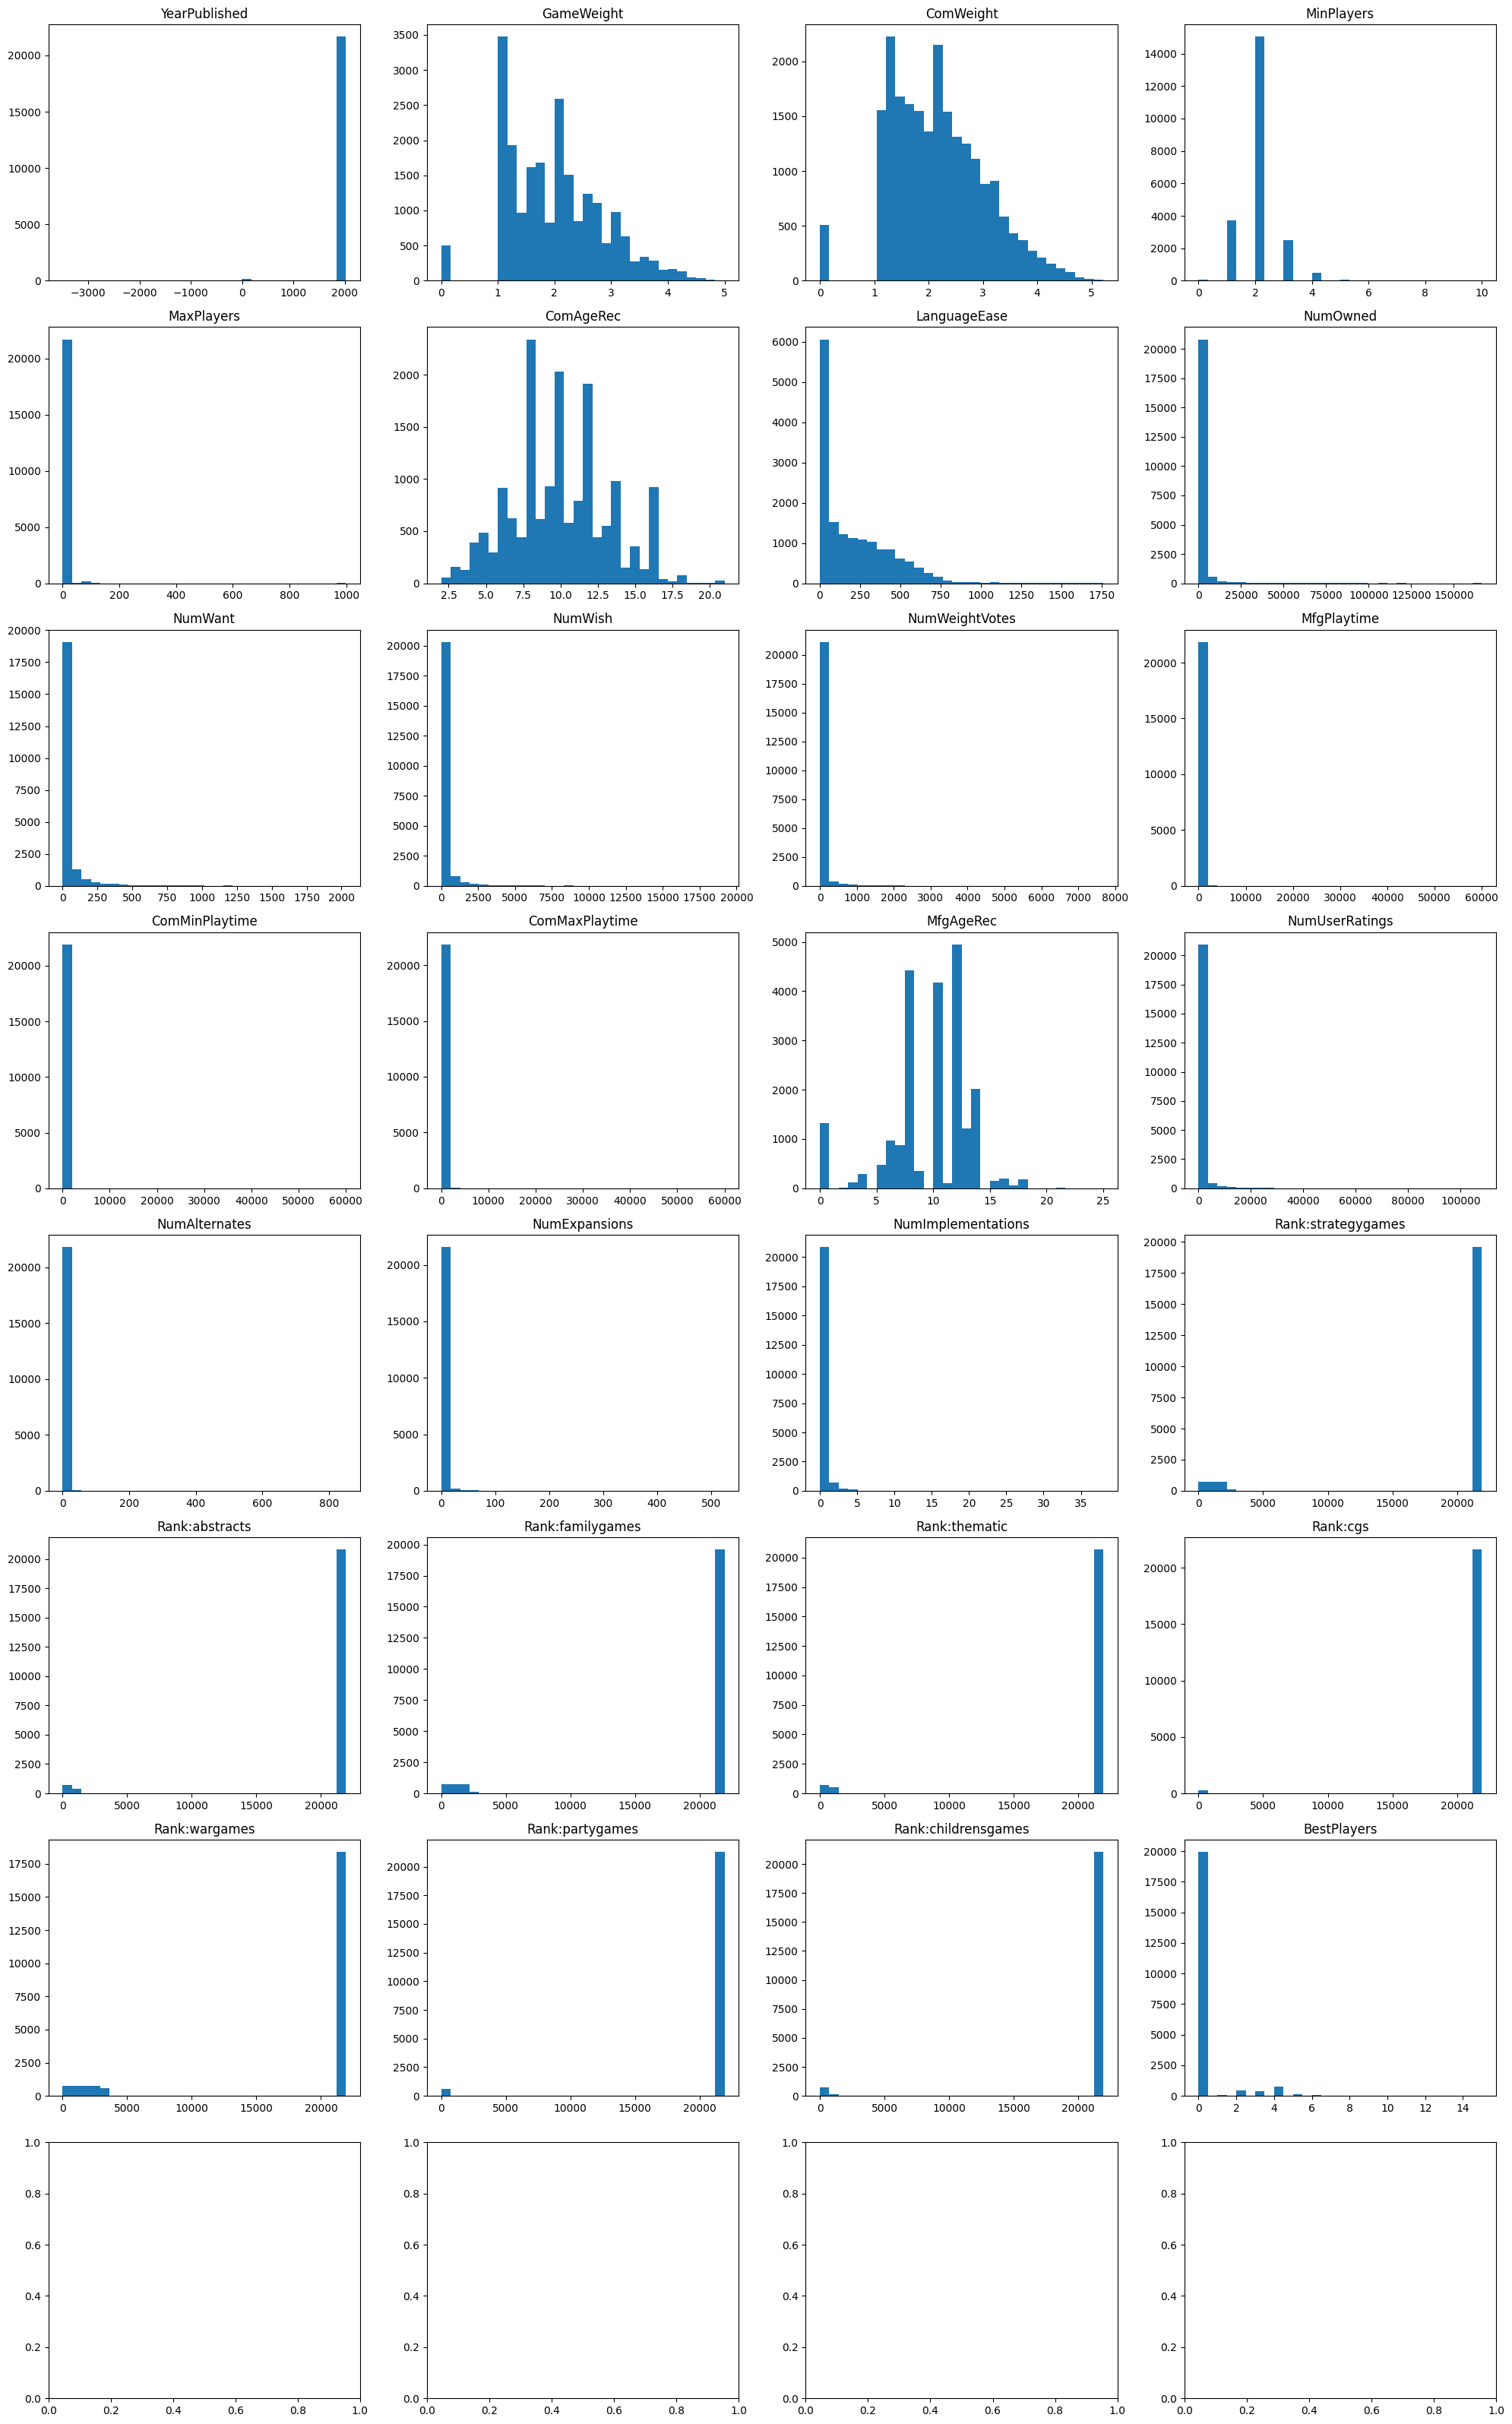

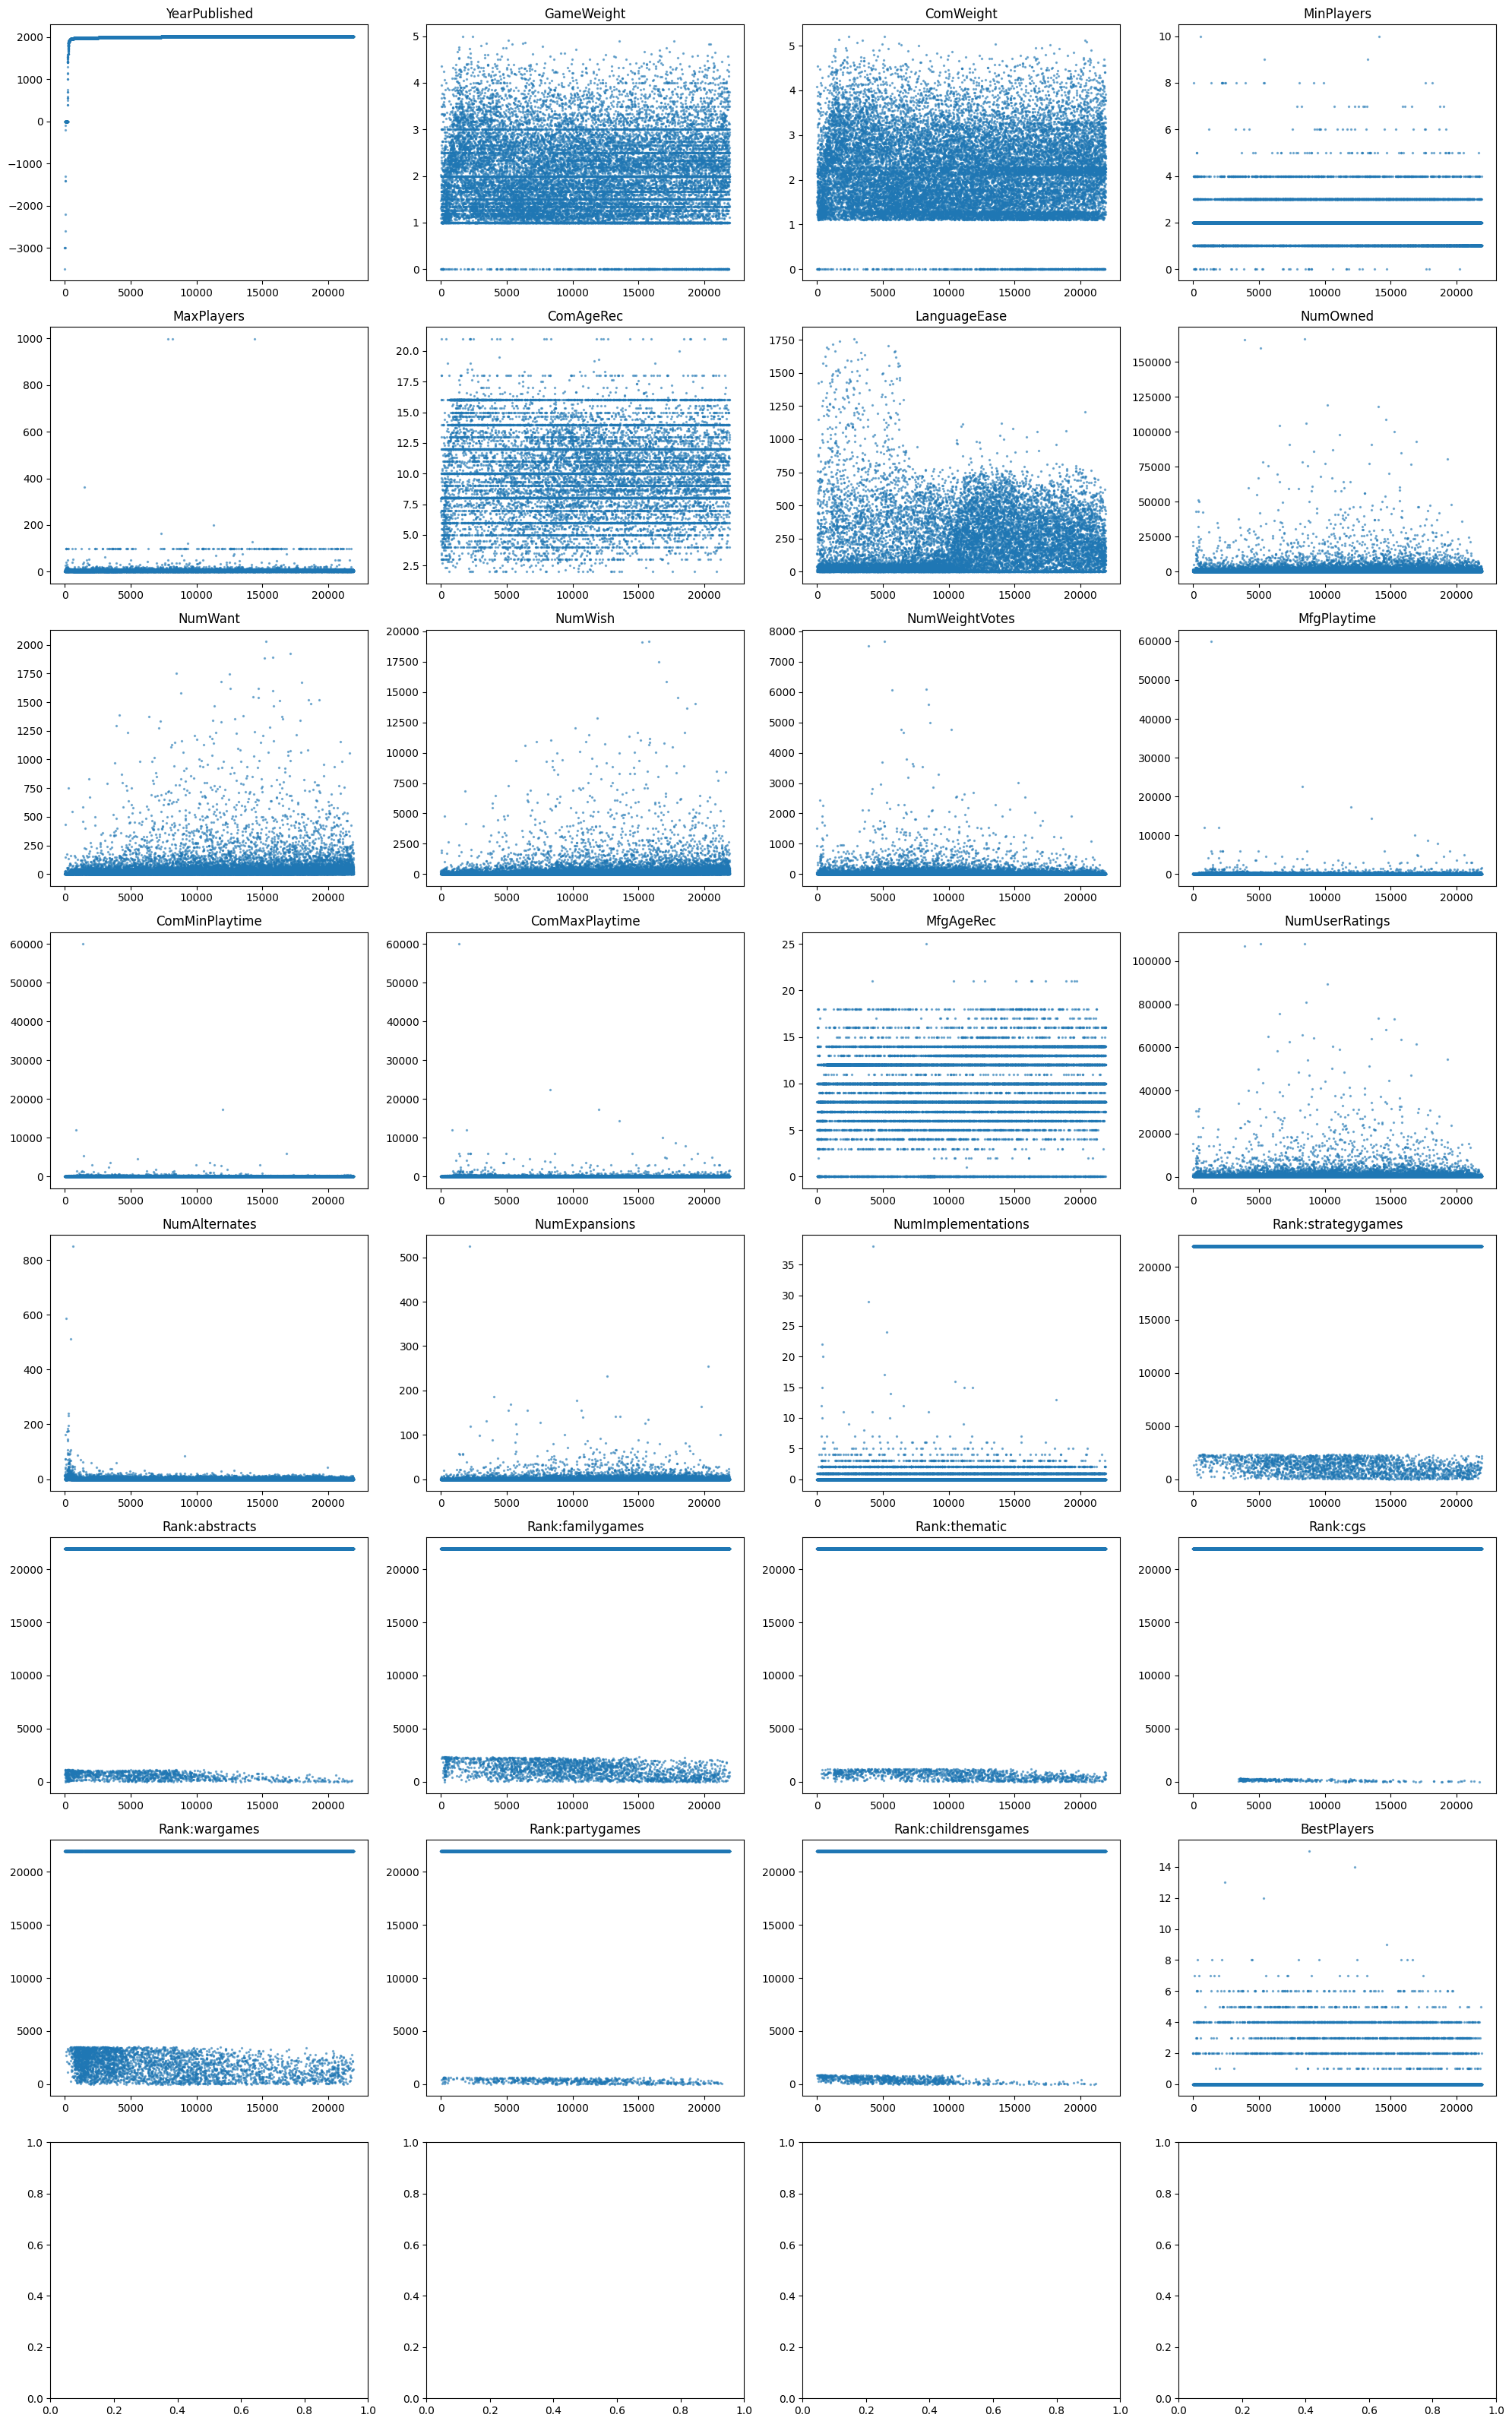

In [135]:
# Quick histograms
fig, axes = plt.subplots(len(numeric_cols)//4 + 1, 4, figsize=(20, 4 * (len(numeric_cols)//4 + 1)))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(df_clean[col].dropna(), bins=30)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# Scatterplots vs index: simple anomaly spotting
fig, axes = plt.subplots(len(numeric_cols)//4 + 1, 4, figsize=(20, 4 * (len(numeric_cols)//4 + 1)))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.scatter(range(len(df_clean)), df_clean[col], s=2, alpha=0.5)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Step 03: DATA UNDERSTANDING - Count of Missing values

In [136]:
missing = df_clean.isna().sum().sort_values(ascending=False)
missing[missing > 0]

Family          15262
LanguageEase     5891
ComAgeRec        5530
ImagePath          17
Description         1
dtype: int64

The only columns that contain non-default missing values are Family, LanguageEase, ComAgeRec, ImagePath and Description

# Step 04: DATA PREPARATION - Correlation Matrix for preliminary column removal


We start plotting Correlation Matrix before analyzing columns. This helps identify evident colinearity.

Rank:strategygames    -0.233463
Rank:familygames      -0.181144
LanguageEase          -0.138416
Rank:thematic         -0.108303
Rank:partygames       -0.080348
Rank:cgs              -0.015938
MinPlayers            -0.012331
Rank:abstracts        -0.004828
ComMinPlaytime        -0.004488
MfgPlaytime           -0.004383
ComMaxPlaytime        -0.004383
MaxPlayers            -0.002489
ComAgeRec              0.003496
YearPublished          0.008939
Rank:childrensgames    0.024891
Rank:wargames          0.065006
MfgAgeRec              0.071329
ComWeight              0.086402
GameWeight             0.087016
NumAlternates          0.144837
NumExpansions          0.260096
NumImplementations     0.350020
BestPlayers            0.517686
NumWant                0.709185
NumWish                0.814348
NumWeightVotes         0.917185
NumOwned               0.985474
NumUserRatings         1.000000
Name: NumUserRatings, dtype: float64


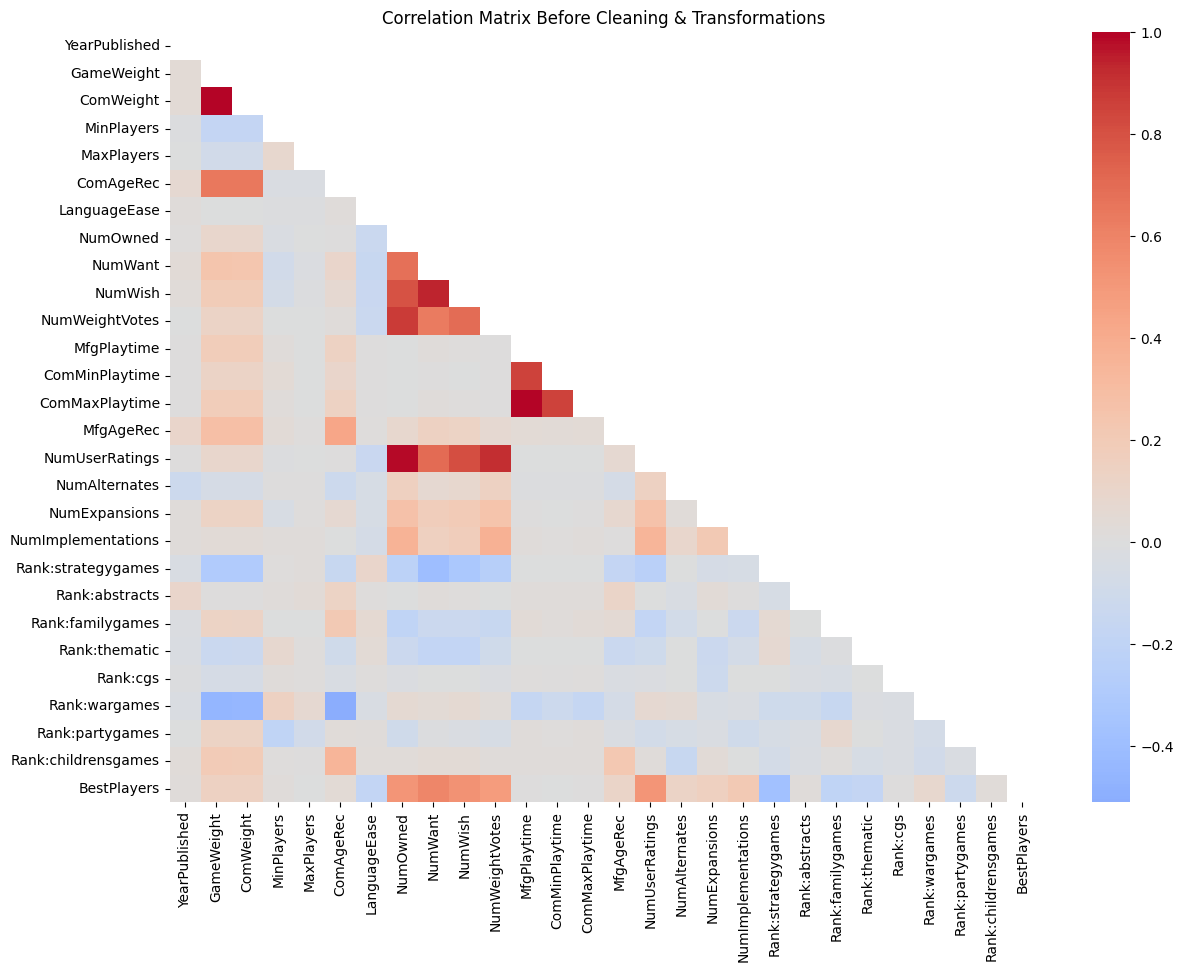

In [137]:
corr_matrix = df_clean[numeric_cols].corr()

print(corr_matrix['NumUserRatings'].sort_values())

trimask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0,mask=trimask)
plt.title("Correlation Matrix Before Cleaning & Transformations")
plt.show()

Some higly correlated columns were identified.

# Step 05: Removing non-significant columns by content

All variables with no statistical information are removed:
- Name 
- Description
- ImagePath
- Family
- GoodPlayers

All rank columns are removed because:
- Each rank contains a small percentage of the whole dataset.
- The increase in complexity they cause is not justified by the information they provide.

As for the other variables:
- NumComments: all records contain `0`.
- ComWeight: its correlation value with GameWeight is `0.99`.
- BestPlayers: the value is mostly 0 (>95%) and was considered as a missing value.
- MfgPlayTime: its correlation value with ComMaxPlaytime is `1`.
- NumWish: it's highly correlated with NumOwned (`0.80`) and NumWant (`0.94`). We tried creating a new variable representing Interest using it with NumWant (sum and average), but correlation with NumOwned was too high. Also, in BoardGamesGeek, the wish and want status are not mutually exclusive, therefore creating a new variable combining them would not be representative. We chose to keep NumWant instead of NumWish as it's correlation with NumOwned is slightly lower (`0.68`)
- LanguageEase: *this column's interpretability is extremely poor* (_main reason_), because there's not a clear scale/range (like GameWeight). About 25% of its data is missing but, unlike ComAgeRec, it's imputation (same method as ComAgeRec) failed with $R^2$ lower than 0.1 and average errors too high.
- NumWeightVotes & NumUserRatings: these columns are highly correlated with eachother (`0.91`) and with NumOwned (`0.87` and `0.98`, respectively). We kept NumOwned as it's the most interesting variable between the three.

In [138]:
cols_to_drop = [
    # no statistical information
    "Name",
    "Description",
    "ImagePath",
    "Family",
    "GoodPlayers",
    
    
    # all rank columns
    "Rank:strategygames",
    "Rank:abstracts",
    "Rank:familygames",
    "Rank:thematic",
    "Rank:cgs",
    "Rank:wargames",
    "Rank:partygames",
    "Rank:childrensgames",


    "NumComments",
    "ComWeight",
    "BestPlayers",
    "MfgPlaytime",
    "NumWish",
    "LanguageEase",
    "NumWeightVotes",
    "NumUserRatings"

]

df_clean = df_clean.drop(
    columns=[c for c in cols_to_drop if c in df_clean.columns]
)

## Step 06: DATA PREPARATION - YearPublished Cleaning + Creation of variable Age

We filter to keep recent games and create variable Age.

In [139]:
# Remove clearly invalid or historical entries
num_elements = len(df_clean)
df_clean = df_clean[df_clean["YearPublished"] >= 1900].copy()

df_clean['Age'] = datetime.now().year - df_clean['YearPublished']
df_clean.drop(columns=["YearPublished"], inplace=True)

print(f"Dropped {num_elements-len(df_clean)} rows")

Dropped 309 rows


Only 309 rows were dropped, indicating no significant data loss.

## Step 07: DATA PREPARATION - GameWeight cleaning

A GameWeight value of `0` was considered as non-standard missing value.

In [140]:
num_elements = len(df_clean)
df_clean = df_clean.loc[df_clean['GameWeight']>0]
print(f"Dropped {num_elements-len(df_clean)} rows")

Dropped 492 rows


492 rows were dropped, indicating no significant data loss.

## Step 08: DATA PREPARATION - Players cleaning

MinPlayers<=0 are set to 1 and MaxPlayers lower than MinPlayers are set to MinPlayers.

In [141]:
# Replace invalid MinPlayers <= 0 with 1
df_clean.loc[df_clean["MinPlayers"] <= 0, "MinPlayers"] = 1

# Replace MaxPlayers lower than MinPlayers with MinPlayers
df_clean.loc[df_clean["MaxPlayers"] < df_clean["MinPlayers"], "MaxPlayers"] = df_clean["MinPlayers"]

## Step 09: DATA PREPARATION - Playtime cleaning + creation of AvgPlaytime

MaxPlayeTime lower than MinPlayTime are set to MaxPlayeTime.
AvgPlayTime is calculated and values <= 0 are dropped.

In [142]:
df_clean.loc[df_clean["ComMaxPlaytime"] < df_clean["ComMinPlaytime"], "ComMaxPlaytime"] = df_clean["ComMinPlaytime"]

df_clean['AvgPlaytime']=(df_clean["ComMaxPlaytime"] + df_clean["ComMinPlaytime"])/2
df_clean.drop(columns=['ComMaxPlaytime',"ComMinPlaytime"], inplace=True)

num_elements = len(df_clean)
df_clean = df_clean.loc[df_clean['AvgPlaytime']>0]
print(f"Dropped {num_elements-len(df_clean)} rows")

Dropped 551 rows


551 rows were dropped, indicating no significant data loss.

## Step 10: DATA PREPARATION - Model-based imputation for ComAgeRec + cleaning of MfgAgerec + creation of AgeRec

Since ComAgeRec is missing around 25% of the data, we'll try to impute it.

We’ll use RandomForestRegressor with all remaining features, as it's strong against unnecessary data. The model is trained with all labeled data (approx 75%), then splitting it with 80/20.

After model assessment, it was re-trained on all data (75% labeled) and missing rows were predicted.


Non-standard missing MfgAgeRec is filled with ComAgeRec and AgeRec is calculated as their average.

In [143]:

exclude_cols = ["ComAgeRec", "BGGId", "Name"]
age_features = [c for c in df_clean.columns if c not in exclude_cols and is_numeric_dtype(df_clean[c])]

# Use rows where target is known
age_train = df_clean[df_clean["ComAgeRec"].notna()]
X = age_train[age_features]
y = age_train["ComAgeRec"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit imputer on train, apply to train/valid to fill NaNs for regressor
imputer = SimpleImputer(strategy="median")
X_train_i = imputer.fit_transform(X_train)
X_valid_i = imputer.transform(X_valid)

# Fit model
rf = RandomForestRegressor(random_state=42, n_estimators=200, max_depth=10, min_samples_leaf=5)
rf.fit(X_train_i, y_train)

# Predict and print results
y_pred = rf.predict(X_valid_i)
print("R²:", r2_score(y_valid, y_pred))
print("MAE:", mean_absolute_error(y_valid, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_valid, y_pred)))

# Refit on all known-target rows
X_i = imputer.fit_transform(X)
rf_final = RandomForestRegressor(random_state=42, n_estimators=200, max_depth=10, min_samples_leaf=5)
rf_final.fit(X_i, y)

# Predict rows
age_missing = df_clean[df_clean["ComAgeRec"].isna()]
if not age_missing.empty:
    X_missing_i = imputer.transform(age_missing[age_features])
    df_clean.loc[age_missing.index, "ComAgeRec"] = rf_final.predict(X_missing_i)

R²: 0.7084478154210291
MAE: 1.2587965620900694
RMSE: 1.7405405978469362


The model achieved an R² of 0.71 on a held-out validation set, indicating good predictive power and supporting model-based imputation rather than mean/median replacement.


In [144]:
df_clean.loc[df_clean["MfgAgeRec"] == 0 ,"MfgAgeRec"] = df_clean["ComAgeRec"]

df_clean['AgeRec'] = (df_clean["MfgAgeRec"] + df_clean["ComAgeRec"])/2

df_clean.drop(columns =["MfgAgeRec","ComAgeRec"],inplace=True)

/tmp/ipykernel_212925/3984620895.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ 8.66666667  7.          5.25       ...  5.6        10.
 16.        ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_clean.loc[df_clean["MfgAgeRec"] == 0 ,"MfgAgeRec"] = df_clean["ComAgeRec"]


## Step 11: DATA PREPARATION - Log-transform the remaining skewed count features
log1p because count features are:
- extremely right-skewed
- contain zeros so log1p avoids log(0)
- improves clustering + distance-based algorithms

In [145]:
# Count-based features that remain after cleanup
count_cols_to_log = [
    "NumOwned",
    "NumAlternates",
    "NumExpansions",
    "NumImplementations",
    "NumWant",
    "AvgPlaytime",
    "MaxPlayers"

]

# Apply log1p transformation
for col in count_cols_to_log:
    df_clean[col + "_log"] = np.log1p(df_clean[col])

# Quick confirmation
df_clean[[c for c in df_clean.columns if c.endswith("_log")]].head()

,NumOwned_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumWant_log,AvgPlaytime_log,MaxPlayers_log
309,4.983607,2.944439,0.000000,1.098612,0.693147,3.044522,1.945910
310,3.258097,0.000000,0.000000,0.000000,1.098612,2.397895,1.609438
311,3.044522,2.302585,0.000000,0.000000,0.000000,4.110874,1.609438
312,7.522400,1.098612,0.000000,0.000000,1.791759,3.044522,2.197225
313,9.623509,2.995732,0.693147,0.693147,4.330733,4.110874,2.197225


## Step 12: DATA PREPARATION - Post-Transformation Correlation check

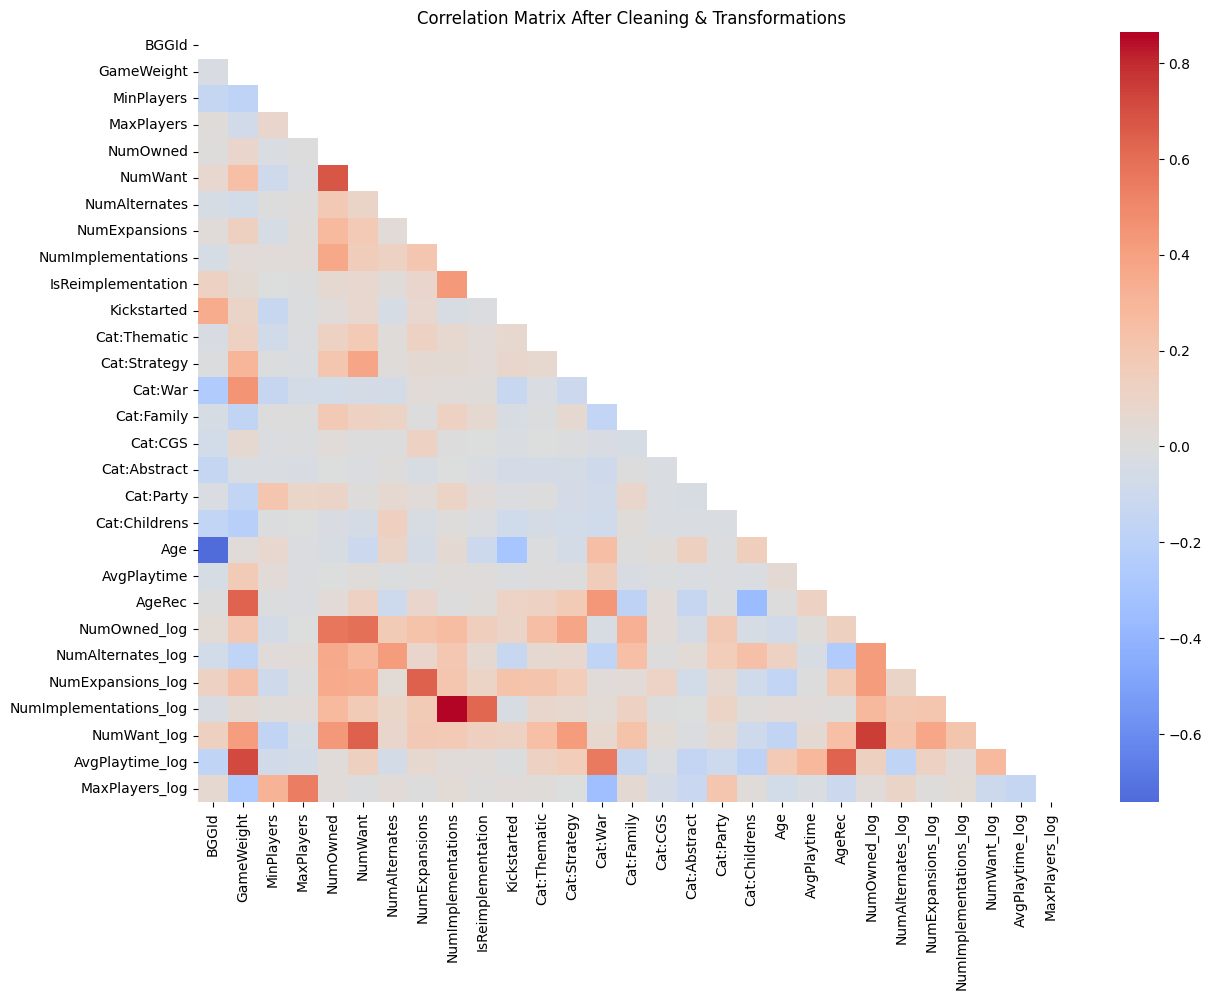

In [147]:
corr_matrix = df_clean.corr(numeric_only=True)

trimask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, mask=trimask)
plt.title("Correlation Matrix After Cleaning & Transformations")
plt.show()

## Step 13: DATA PREPARATION - Final Data Overview

We now check the dataset stats before outputting it.

In [ ]:
print(f"The dataset now contains {len(df_clean.columns)} columns with {len(df_clean)} rows")

print(f"In the data cleaning process {len(df_raw)-len(df_clean)} were lost, with them being {round(1-(len(df_clean)/len(df_raw)),4)*100}% of the original dataset")

print(f"Remaning variables are: \n\n{',\n'.join(df_clean.columns)}")

The dataset now contains 30 columns with 20573 rows
In the data cleaning process 1352 were lost, with them being 6.17% of the original dataset
Remaning variables are: 

BGGId,
GameWeight,
MinPlayers,
MaxPlayers,
NumOwned,
NumWant,
NumAlternates,
NumExpansions,
NumImplementations,
IsReimplementation,
Kickstarted,
Cat:Thematic,
Cat:Strategy,
Cat:War,
Cat:Family,
Cat:CGS,
Cat:Abstract,
Cat:Party,
Cat:Childrens,
Rating,
Age,
AvgPlaytime,
AgeRec,
NumOwned_log,
NumAlternates_log,
NumExpansions_log,
NumImplementations_log,
NumWant_log,
AvgPlaytime_log,
MaxPlayers_log


In [165]:
df_clean.to_csv("df_prepared.csv", index=False)
print("Saved df_prepared.csv")

Saved df_prepared.csv
